# Figure 6 (v2) — what distinguishes the dynamic modes across contexts

Figure 6 asks which features set apart genes in each dynamic response mode, in K562 (TNF-alpha) and
THP1 (LPS):

- **Dot plot:**
  - pathway over-representation (ORA);
  - gene covariates (length, mRNA decay, ARE motifs);
  - promoter (PLS) motifs (NF-kB, AP-1, CRE, TATA).
- **6d / 6e:** elastic-net and OLS regressions of kinetic outcomes (onset, peak, persistence, ...)
  on promoter architecture, enhancer architecture, enhancer burden, RNA stability and gene length.
- **Full-model and family-only CV R²:** how much each outcome is predictable overall, and from each family alone.

v2 draws the regression panels from the v4 kinetics tables of `Fig6_Reproduction/reference/kinetics/`, which
supersede the Run3 tables used by `Fig6_CrossContext/`.

The panels plot precomputed analysis tables copied into `input/`. The plotting functions are called
directly in this notebook. By default the existing outputs are shown; set `RERUN = True` to redraw
them. The last section checks the inputs against the reference manifest and compares the figures with v1.

## Setup

In [1]:
import os
import sys
from pathlib import Path

FIG_DIR = Path.cwd()  # the notebook runs from its figure folder
sys.path.insert(0, str(FIG_DIR / "scripts"))
from nb_helpers import needs_run, run, show_image, show_table, show_text

# False: show the existing outputs (steps only run if an output is missing).
# True:  regenerate every step. Batch runs can set FIG_RERUN=1 instead of editing this cell.
RERUN = os.environ.get("FIG_RERUN", "0") == "1"

import matplotlib as mpl
import pandas as pd

import plot_fig6_dotplot as dotplot   # ORA + covariate + PLS-motif dot plot
import plot_fig6de as de              # regression-screen panels 6d / 6e / composite
import plot_fig6_full_model_r2 as full_r2   # full-model CV R²
import plot_fig6_family_only_r2 as fam_r2  # family-only CV R²


def reset_style():
    """Match the command-line scripts: matplotlib defaults, not the notebook's inline settings."""
    mpl.rcdefaults()

print("RERUN =", RERUN)

RERUN = False


## Inputs

| File | Used for |
|---|---|
| `ORA_results_v2_newbg_newfg4.csv`, `curated_ordered_grouped_specific_terms.csv` | ORA rows (curated terms, grouped by mode) |
| `logistic_regression_screen_results_v3_b3_pctl_fg4.csv` | covariate rows (logistic regression screen, percentile covariates) |
| `motif_summary_S10_CRE-matched_with_counts.csv`, `tata_box_positional_S10_summary_with_counterfactual_q.csv` | PLS motif rows (TATA from the positional summary) |
| `cv_summary_results.csv` | 6d (drop-one-family CV ΔR²), full-model and family-only CV R² |
| `canonical9_ols_results.csv` | 6e (per-feature partial R²) |
| `cv_celltype_only_results.csv` | cell-type-only baseline (full-model diamonds, family-only gain) |

All eight are copied unchanged from `Fig6_Reproduction/reference/`.

The curated ORA terms:

In [2]:
show_table("input/curated_ordered_grouped_specific_terms.csv", n=None);

,mode,Description,display
0,Shared induced,HALLMARK_TNFA_SIGNALING_VIA_NFKB,TNFa/NF-kB
1,Shared induced,COLLECTRI_RELA,RELA
2,Shared induced,COLLECTRI_JUN,JUN
3,Shared induced,GOBP_INFLAMMATORY_RESPONSE,Inflammatory Response
4,Impulse Up 1 - rapid inflammatory/effector,GOBP_REGULATION_OF_APOPTOTIC_SIGNALING_PATHWAY,Apoptotic Signaling Reg.
5,Impulse Up 1 - rapid inflammatory/effector,REACTOME_CHEMOKINE_RECEPTORS_BIND_CHEMOKINES,Chemokine Receptors
6,Impulse Up 1 - rapid inflammatory/effector,KEGG_CHEMOKINE_SIGNALING_PATHWAY,Chemokine Signaling
7,Impulse Up 1 - rapid inflammatory/effector,GOBP_MYELOID_LEUKOCYTE_MIGRATION,Myeloid Leukocyte Migration
8,Impulse Up 2 - secondary MAPK/regulatory,GOBP_JNK_CASCADE,JNK Cascade
9,Impulse Up 2 - secondary MAPK/regulatory,GOBP_P38MAPK_CASCADE,p38 MAPK Cascade


## Dot plot — ORA, covariates and PLS motifs

Columns are dynamic modes × context (circle = K562, square = THP1). Black outlines mark q < 0.05.

| Rows | Colour | Size |
|---|---|---|
| ORA | log2 fold enrichment | gene ratio |
| Covariates | log2 odds from the logistic screen | −log10 p |
| PLS motifs | log2 Fisher enrichment | −log10 p |

Using existing outputs (set RERUN = True to regenerate).


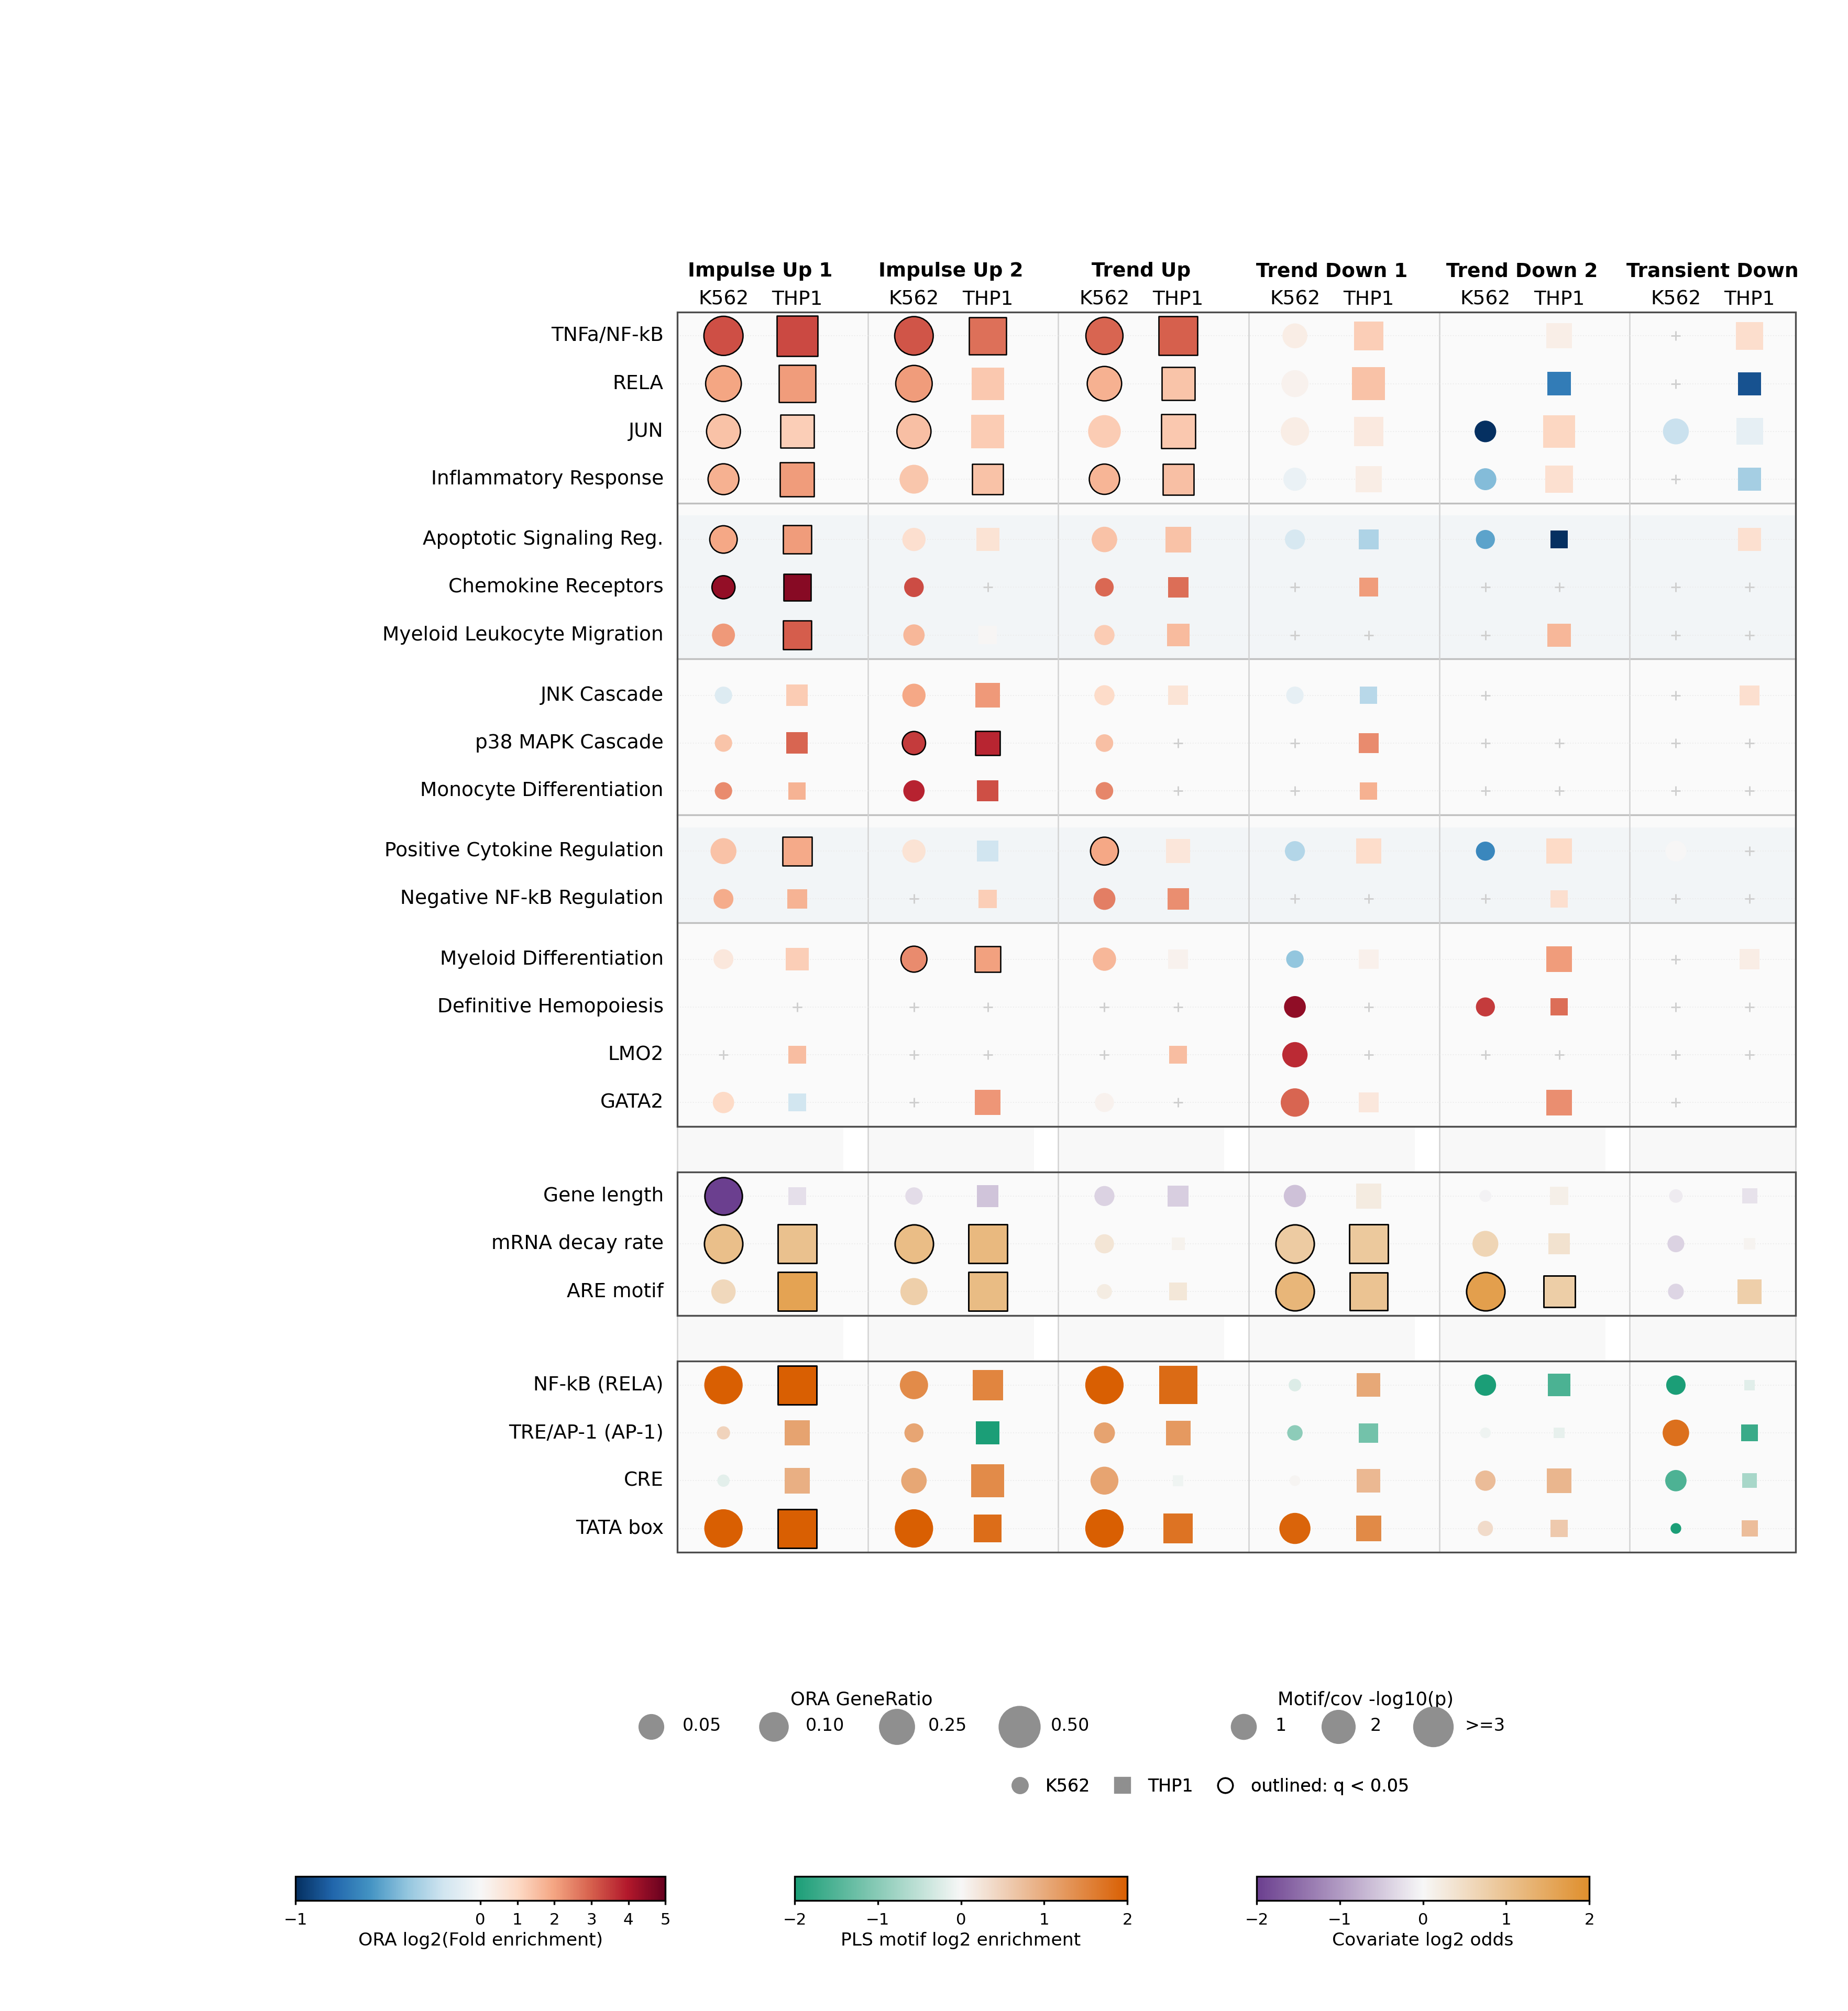

In [3]:
dot_prefix = "output/fig6_ora_cov_pls_motifs_transposed_v2_pctl_fg4_q05"
if needs_run([dot_prefix + ".png", dot_prefix + "_points.csv"], RERUN):
    reset_style()
    covariate_csv, out_prefix = dotplot.VARIANTS["v2"]
    dotplot.plot_variant(covariate_csv, out_prefix, "q05")
show_image(dot_prefix + ".png", width=750)

Outlined (q < 0.05) points per panel:

In [4]:
points = pd.read_csv(FIG_DIR / (dot_prefix + "_points.csv"))
points.groupby("panel", sort=False)["outlined"].agg(["sum", "size"]).rename(columns={"sum": "outlined", "size": "points"})

,outlined,points
panel,,
ORA,31,136
Covariates,13,36
PLS motifs,2,48


## 6d — which feature families carry unique predictive signal?

An elastic-net model predicts each kinetic outcome from all feature families. Each cell is the
cross-validated R² lost when one family is dropped. Positive values mean the family carries signal
the others do not.

Using existing outputs (set RERUN = True to regenerate).


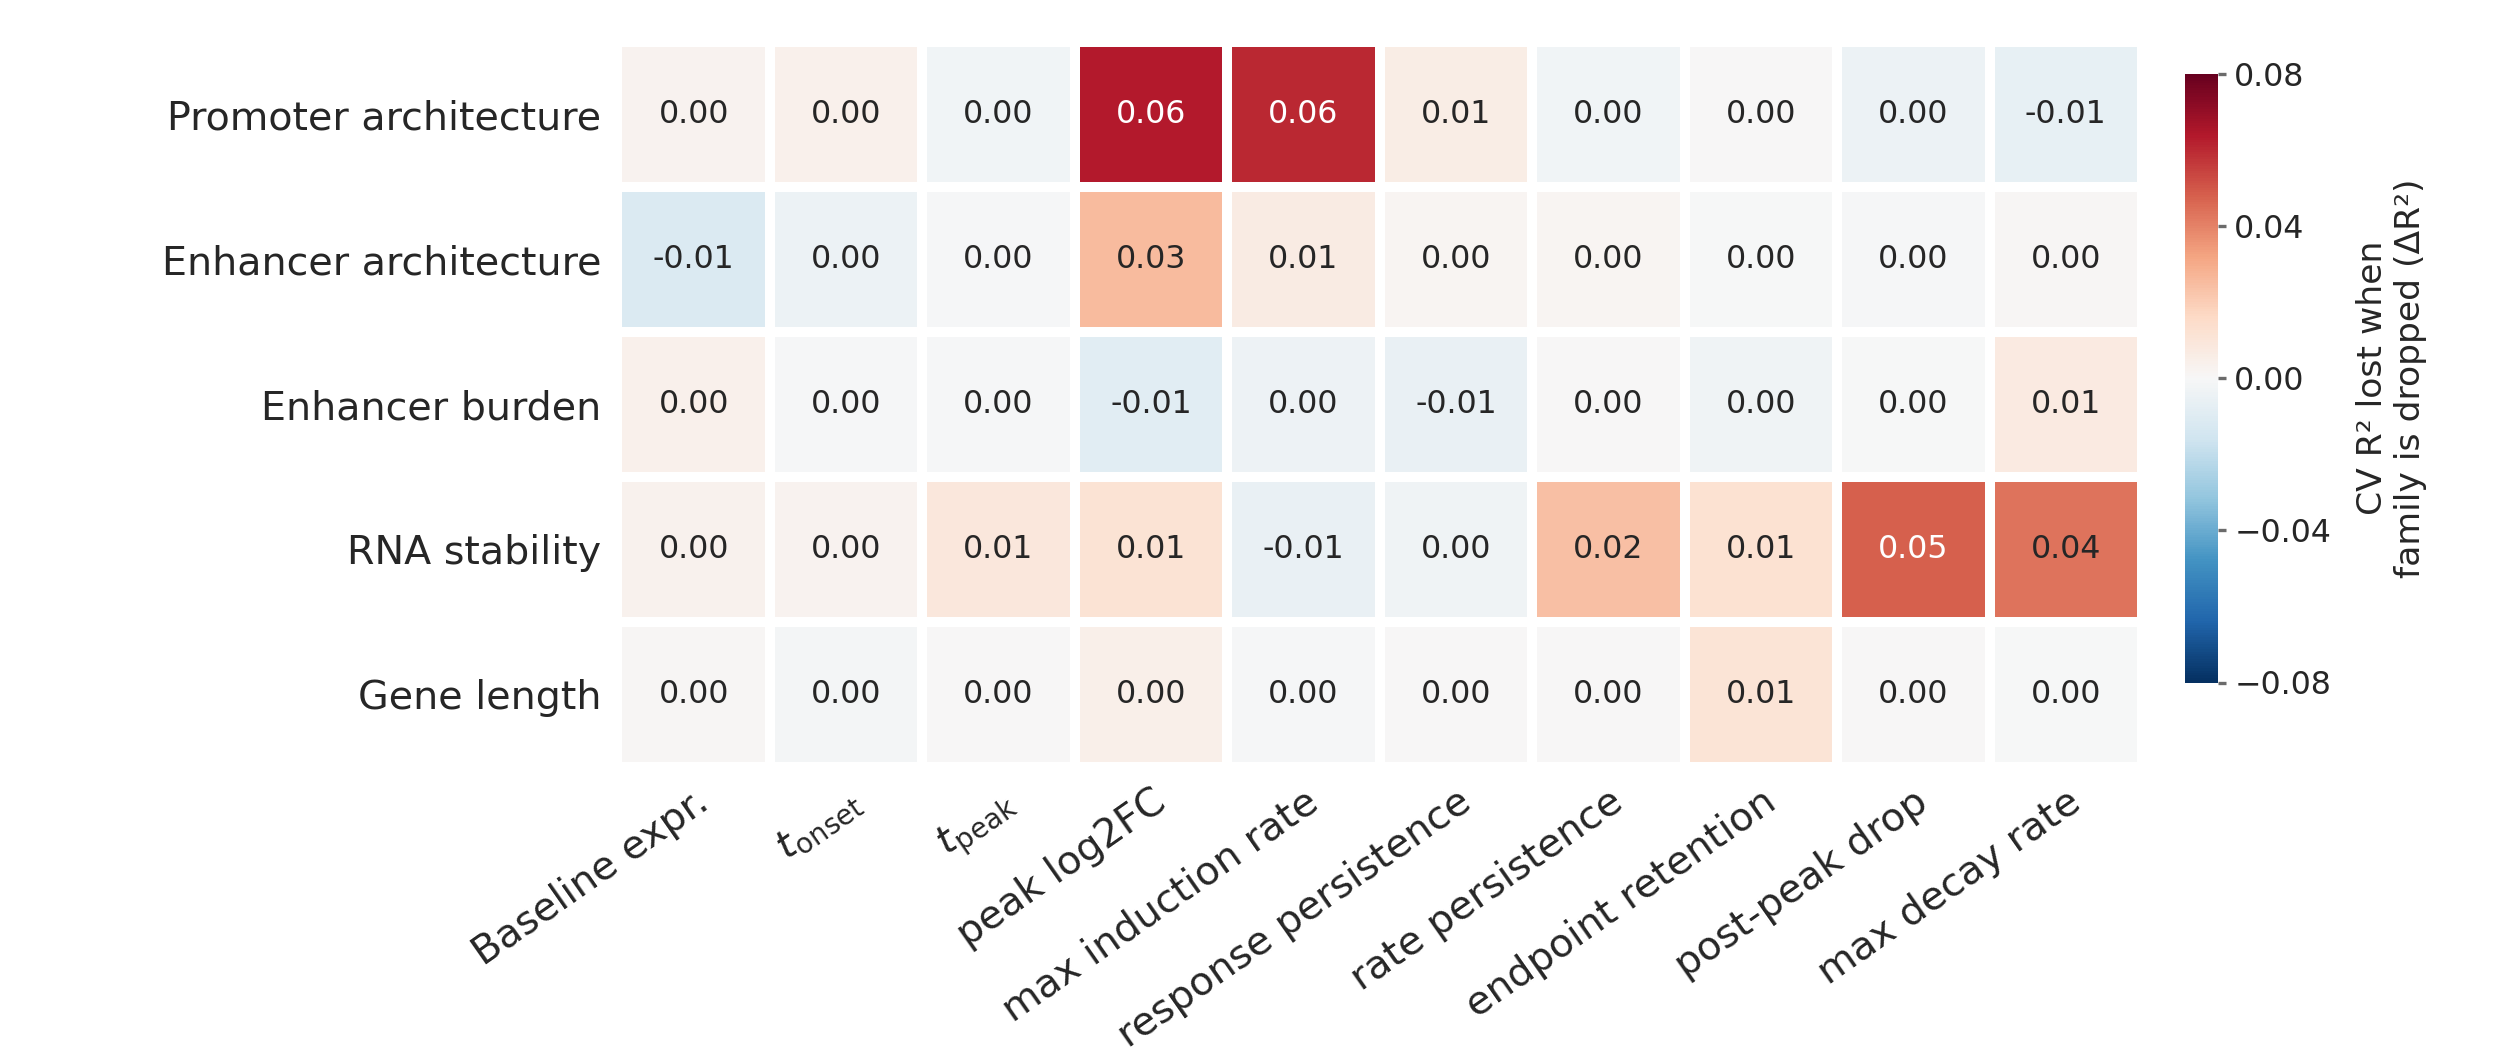

outcome,baseline_exp,endpoint_retention,max_decay_rate,max_induction_rate,owp,owp_ddt,peak_log2fc,postpeak_drop,t_onset,t_peak
family,,,,,,,,,,
enhancer_architecture,-0.012,-0.001,0.001,0.007,0.002,0.002,0.026,-0.001,-0.004,-0.001
enhancer_burden,0.004,-0.003,0.007,-0.004,-0.006,0.000,-0.009,-0.000,-0.001,-0.001
gene_length,0.001,0.011,-0.000,-0.001,0.000,0.000,0.005,0.000,-0.001,0.000
promoter_architecture,0.003,0.000,-0.006,0.060,0.006,-0.003,0.064,-0.005,0.004,-0.003
rna_stability,0.003,0.012,0.044,-0.006,-0.003,0.024,0.011,0.048,0.003,0.009


In [5]:
d_prefix = "output/fig6d_drop_one_family_delta_r2"
if needs_run([d_prefix + ".png", d_prefix + "_values.csv"], RERUN):
    reset_style(); de.set_style()
    de.plot_d()
show_image(d_prefix + ".png", width=850)
pd.read_csv(FIG_DIR / (d_prefix + "_values.csv")).pivot(index="family", columns="outcome", values="delta_r2").round(3)

## 6e — individual feature associations

Each feature has its own OLS regression for each outcome, adjusted for cell type:
- **Dot area:** partial R².
- **Colour:** sign of the coefficient.
- **Black ring:** FDR < 0.05.

Using existing outputs (set RERUN = True to regenerate).


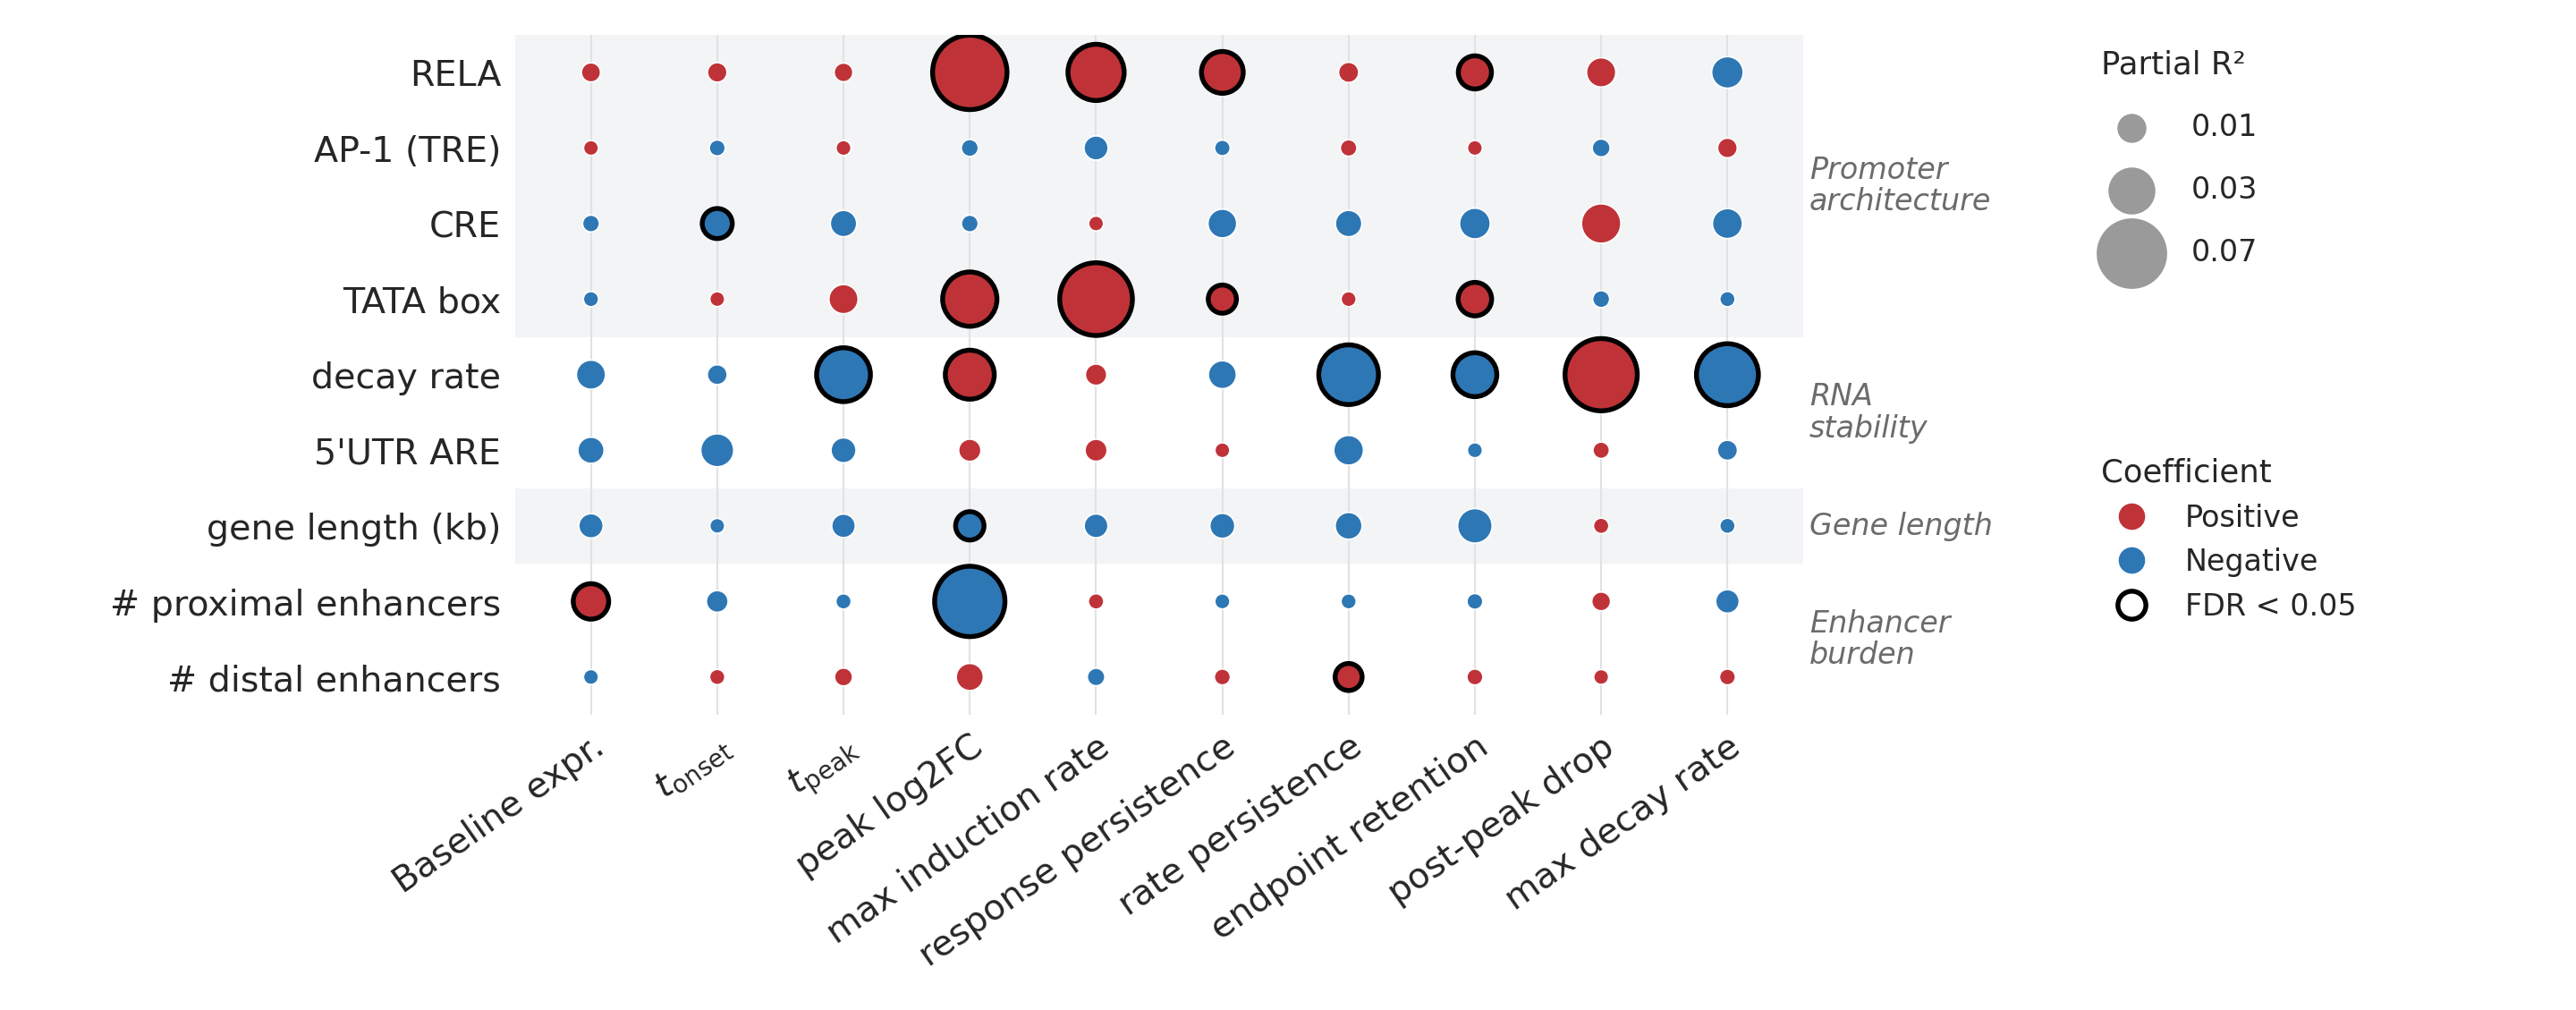

,predictor,outcome,coef,partial_r2,padj_fdr
3,RELA_in_PLS,peak_log2fc,0.630836,0.074974,0.000009
34,is_TATA_strict,max_induction_rate,0.843636,0.071455,0.026196
48,median_log10_decay_rate,postpeak_drop,0.270341,0.070477,0.000007
73,n_pELS,peak_log2fc,-0.236873,0.066688,0.000001
49,median_log10_decay_rate,max_decay_rate,-0.234894,0.050985,0.000592
46,median_log10_decay_rate,owp_ddt,-0.229995,0.047132,0.000004
4,RELA_in_PLS,max_induction_rate,0.483601,0.041471,0.023795
33,is_TATA_strict,peak_log2fc,0.579881,0.038487,0.005433
42,median_log10_decay_rate,t_peak,-0.174795,0.037760,0.000082
43,median_log10_decay_rate,peak_log2fc,0.164002,0.030682,0.002023


In [6]:
e_prefix = "output/fig6e_individual_partial_r2"
if needs_run([e_prefix + ".png", e_prefix + "_values.csv"], RERUN):
    reset_style(); de.set_style()
    de.plot_e()
show_image(e_prefix + ".png", width=900)
e_vals = pd.read_csv(FIG_DIR / (e_prefix + "_values.csv"))
e_vals[e_vals["significant"]].sort_values("partial_r2", ascending=False)[["predictor", "outcome", "coef", "partial_r2", "padj_fdr"]].head(15)

## 6d + 6e composite (260 × 90 mm)

Using existing outputs (set RERUN = True to regenerate).


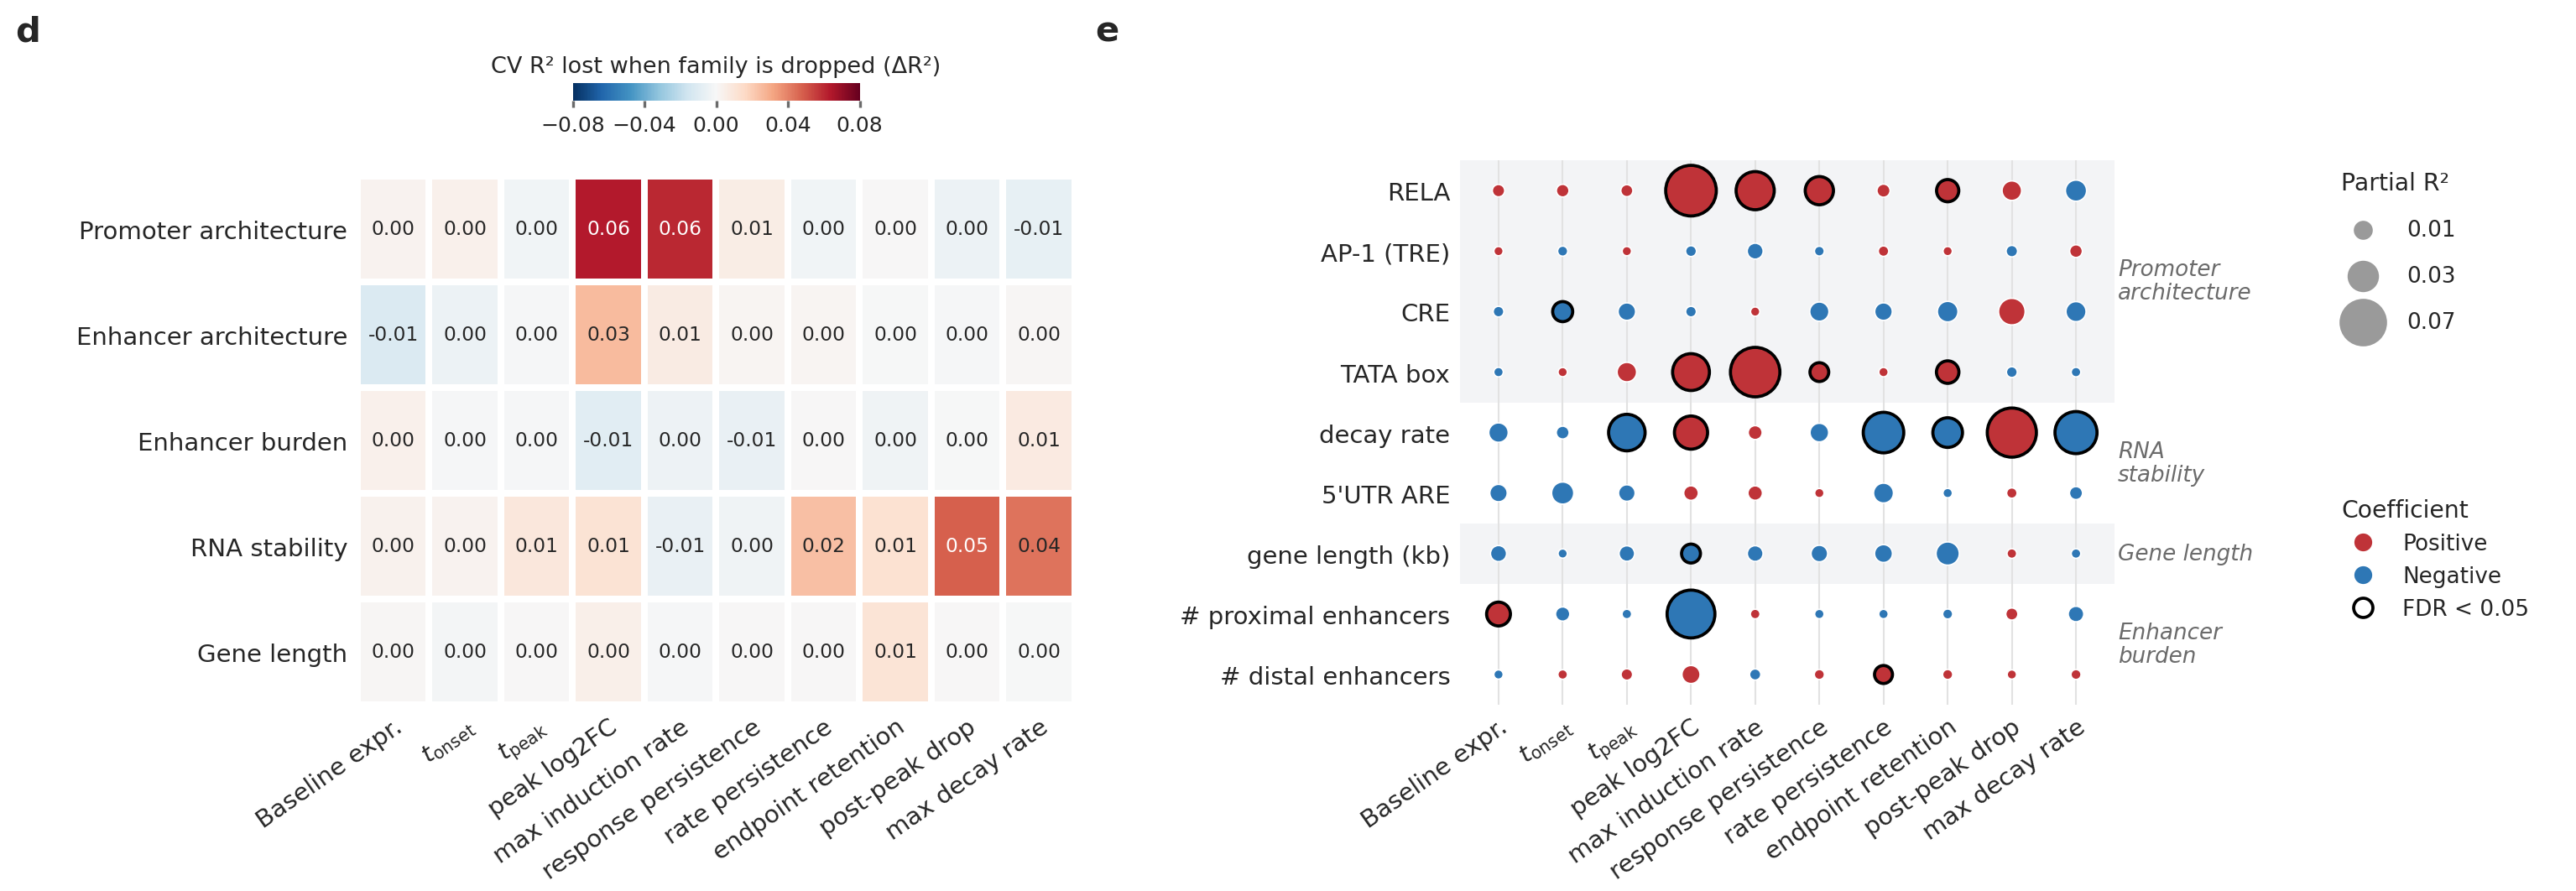

In [7]:
de_prefix = "output/fig6de_composite"
if needs_run([de_prefix + ".png"], RERUN):
    reset_style(); de.set_style()
    de.plot_composite()
show_image(de_prefix + ".png", width=1100)

## Full-model CV R² per outcome

Bars: elastic-net CV R² of the full model (mean ± SD over 10 CV repeats). Diamonds: the cell-type-only model.

Using existing outputs (set RERUN = True to regenerate).


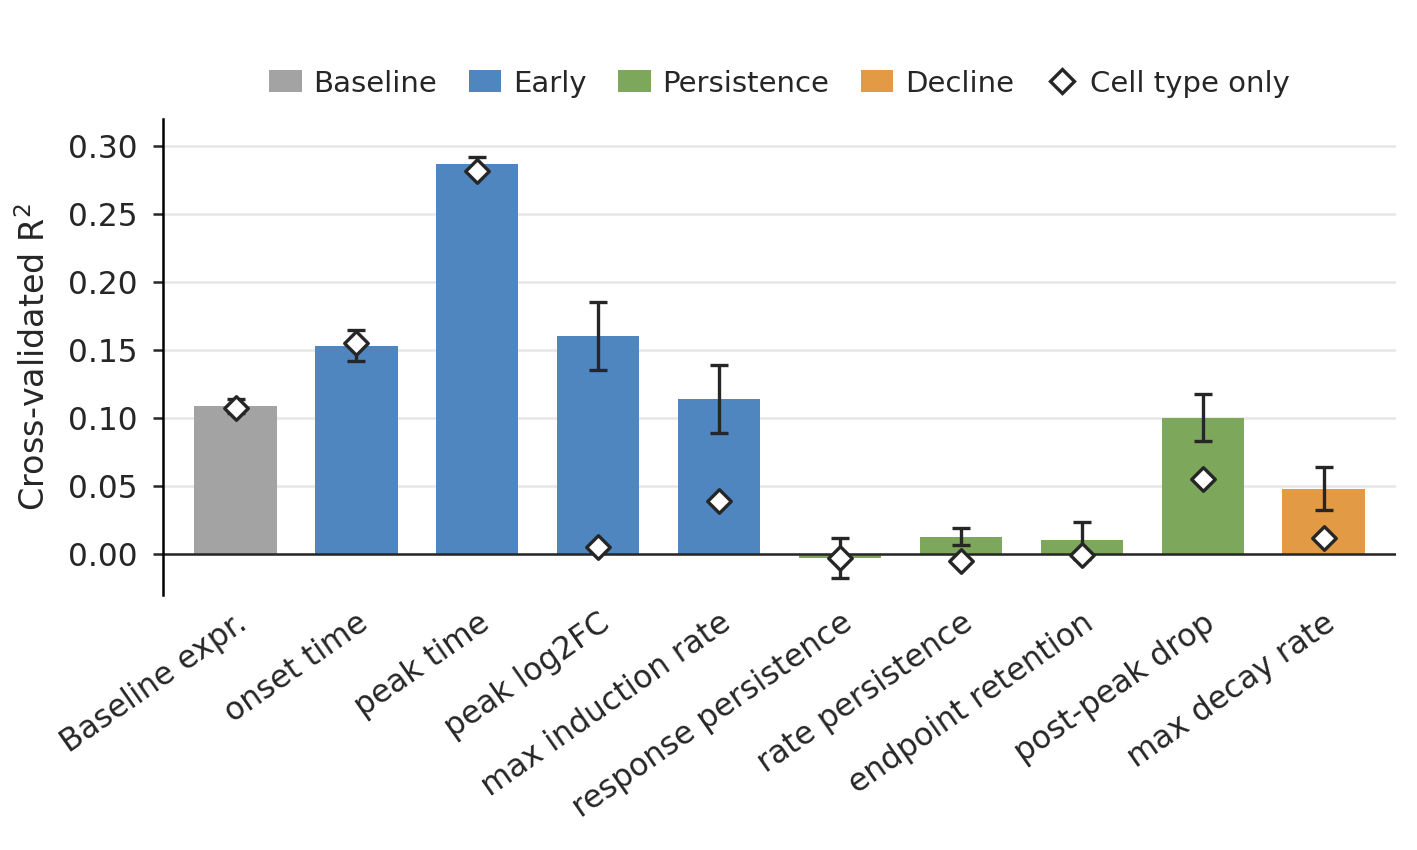

In [8]:
full_prefix = "output/fig6_full_model_cv_r2"
if needs_run([full_prefix + ".png", full_prefix + "_values.csv"], RERUN):
    reset_style(); de.set_style()
    full_r2.plot(full_r2.load_values())
show_image(full_prefix + ".png", width=650)

## Family-only CV R² — what does each family predict on its own?

Each family-only model uses one feature family plus cell type, so its raw R² includes what cell type alone
explains (which dominates the timing outcomes). The main figure shows the gain over the cell-type-only model;
the raw family-only R² follows, with cell type alone as the top row. Read with 6d: 6d is the signal a family
carries that the others do not; this is the signal it carries alone.

Using existing outputs (set RERUN = True to regenerate).


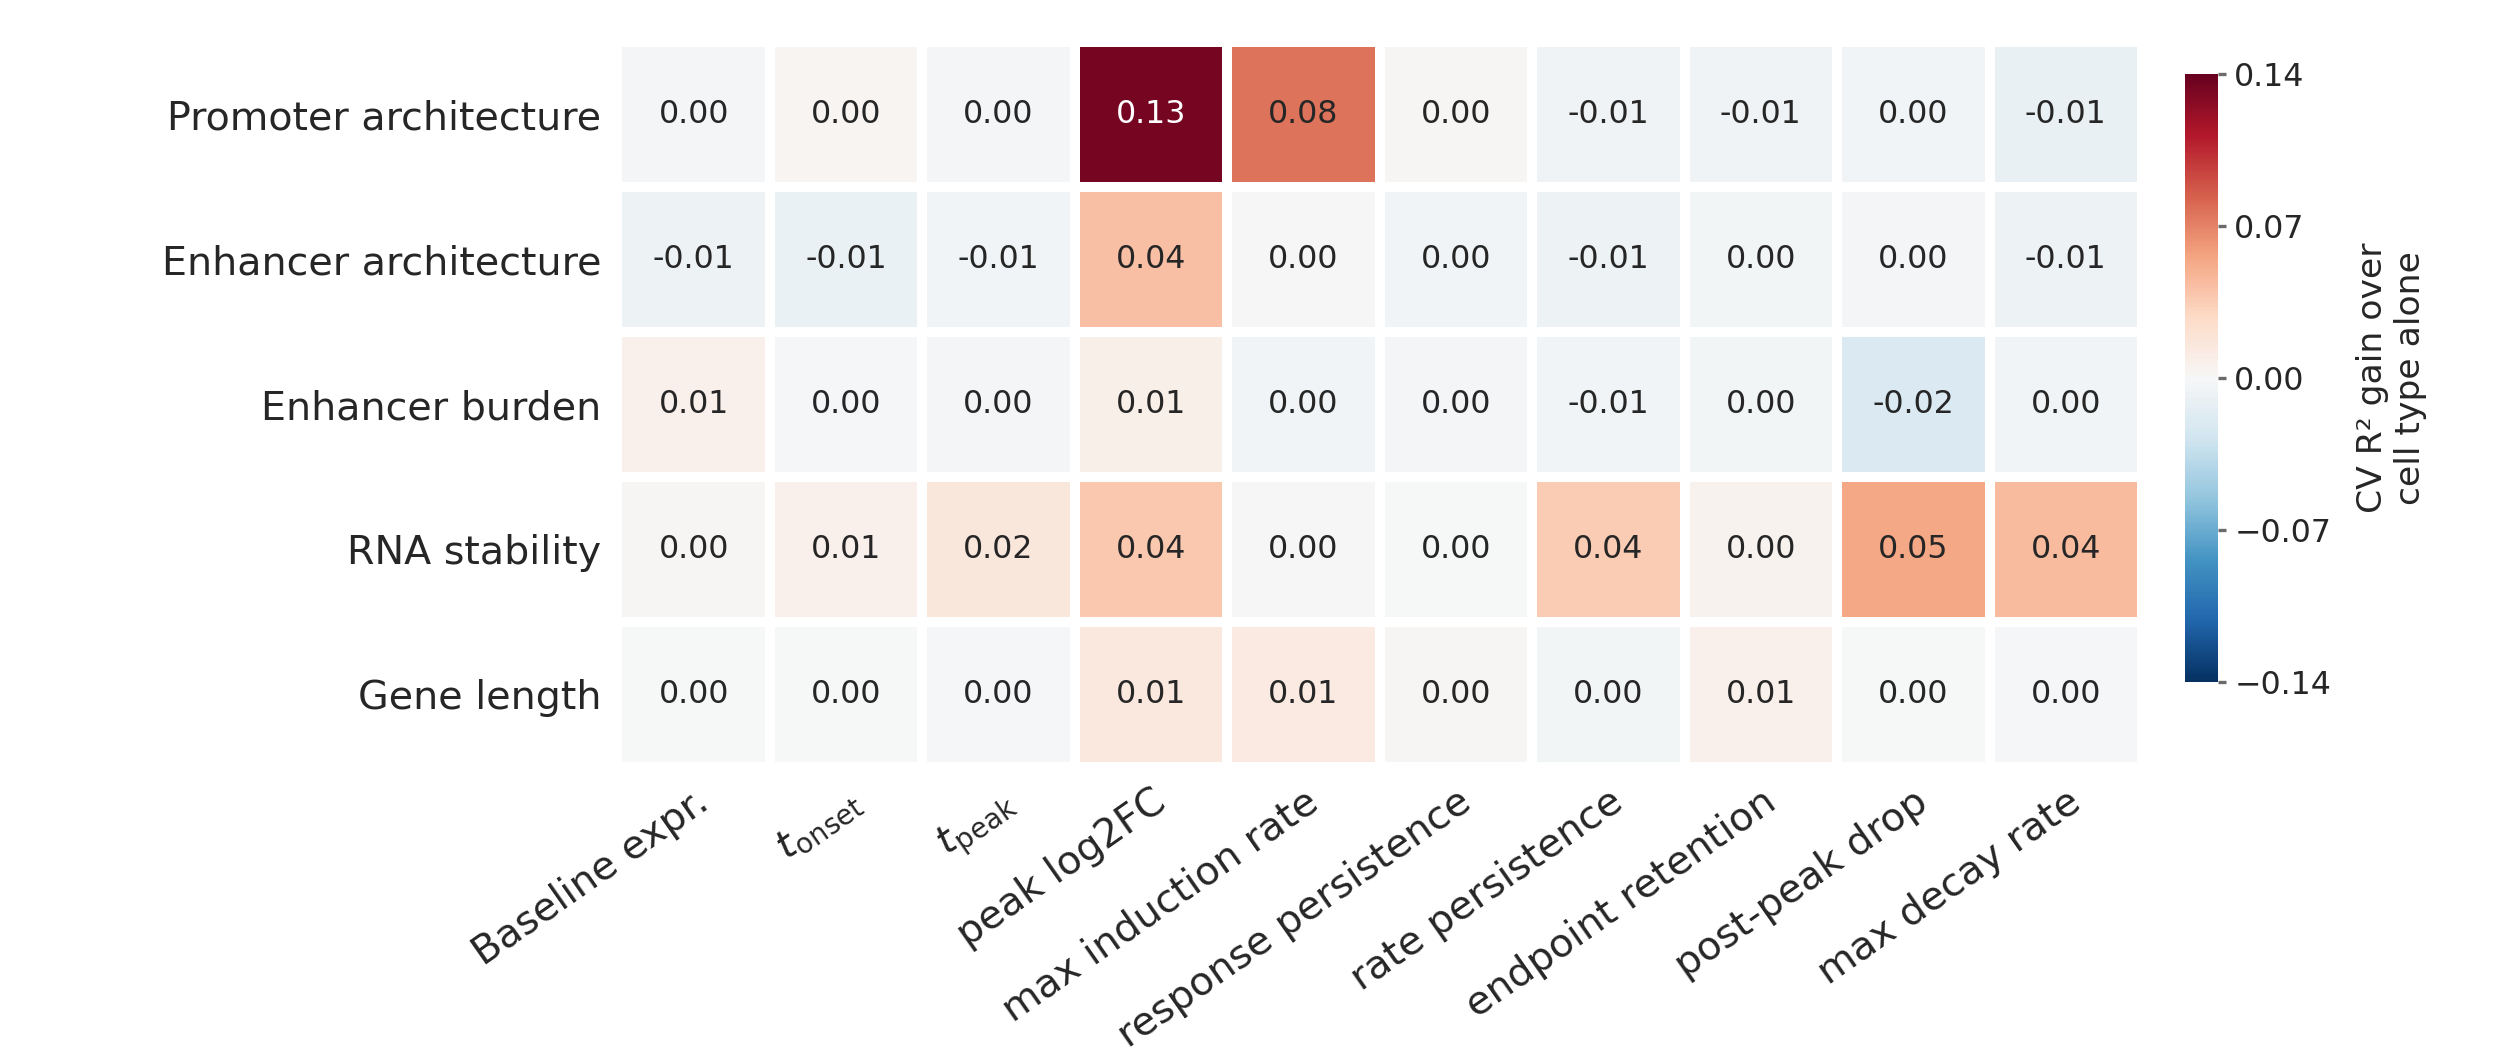

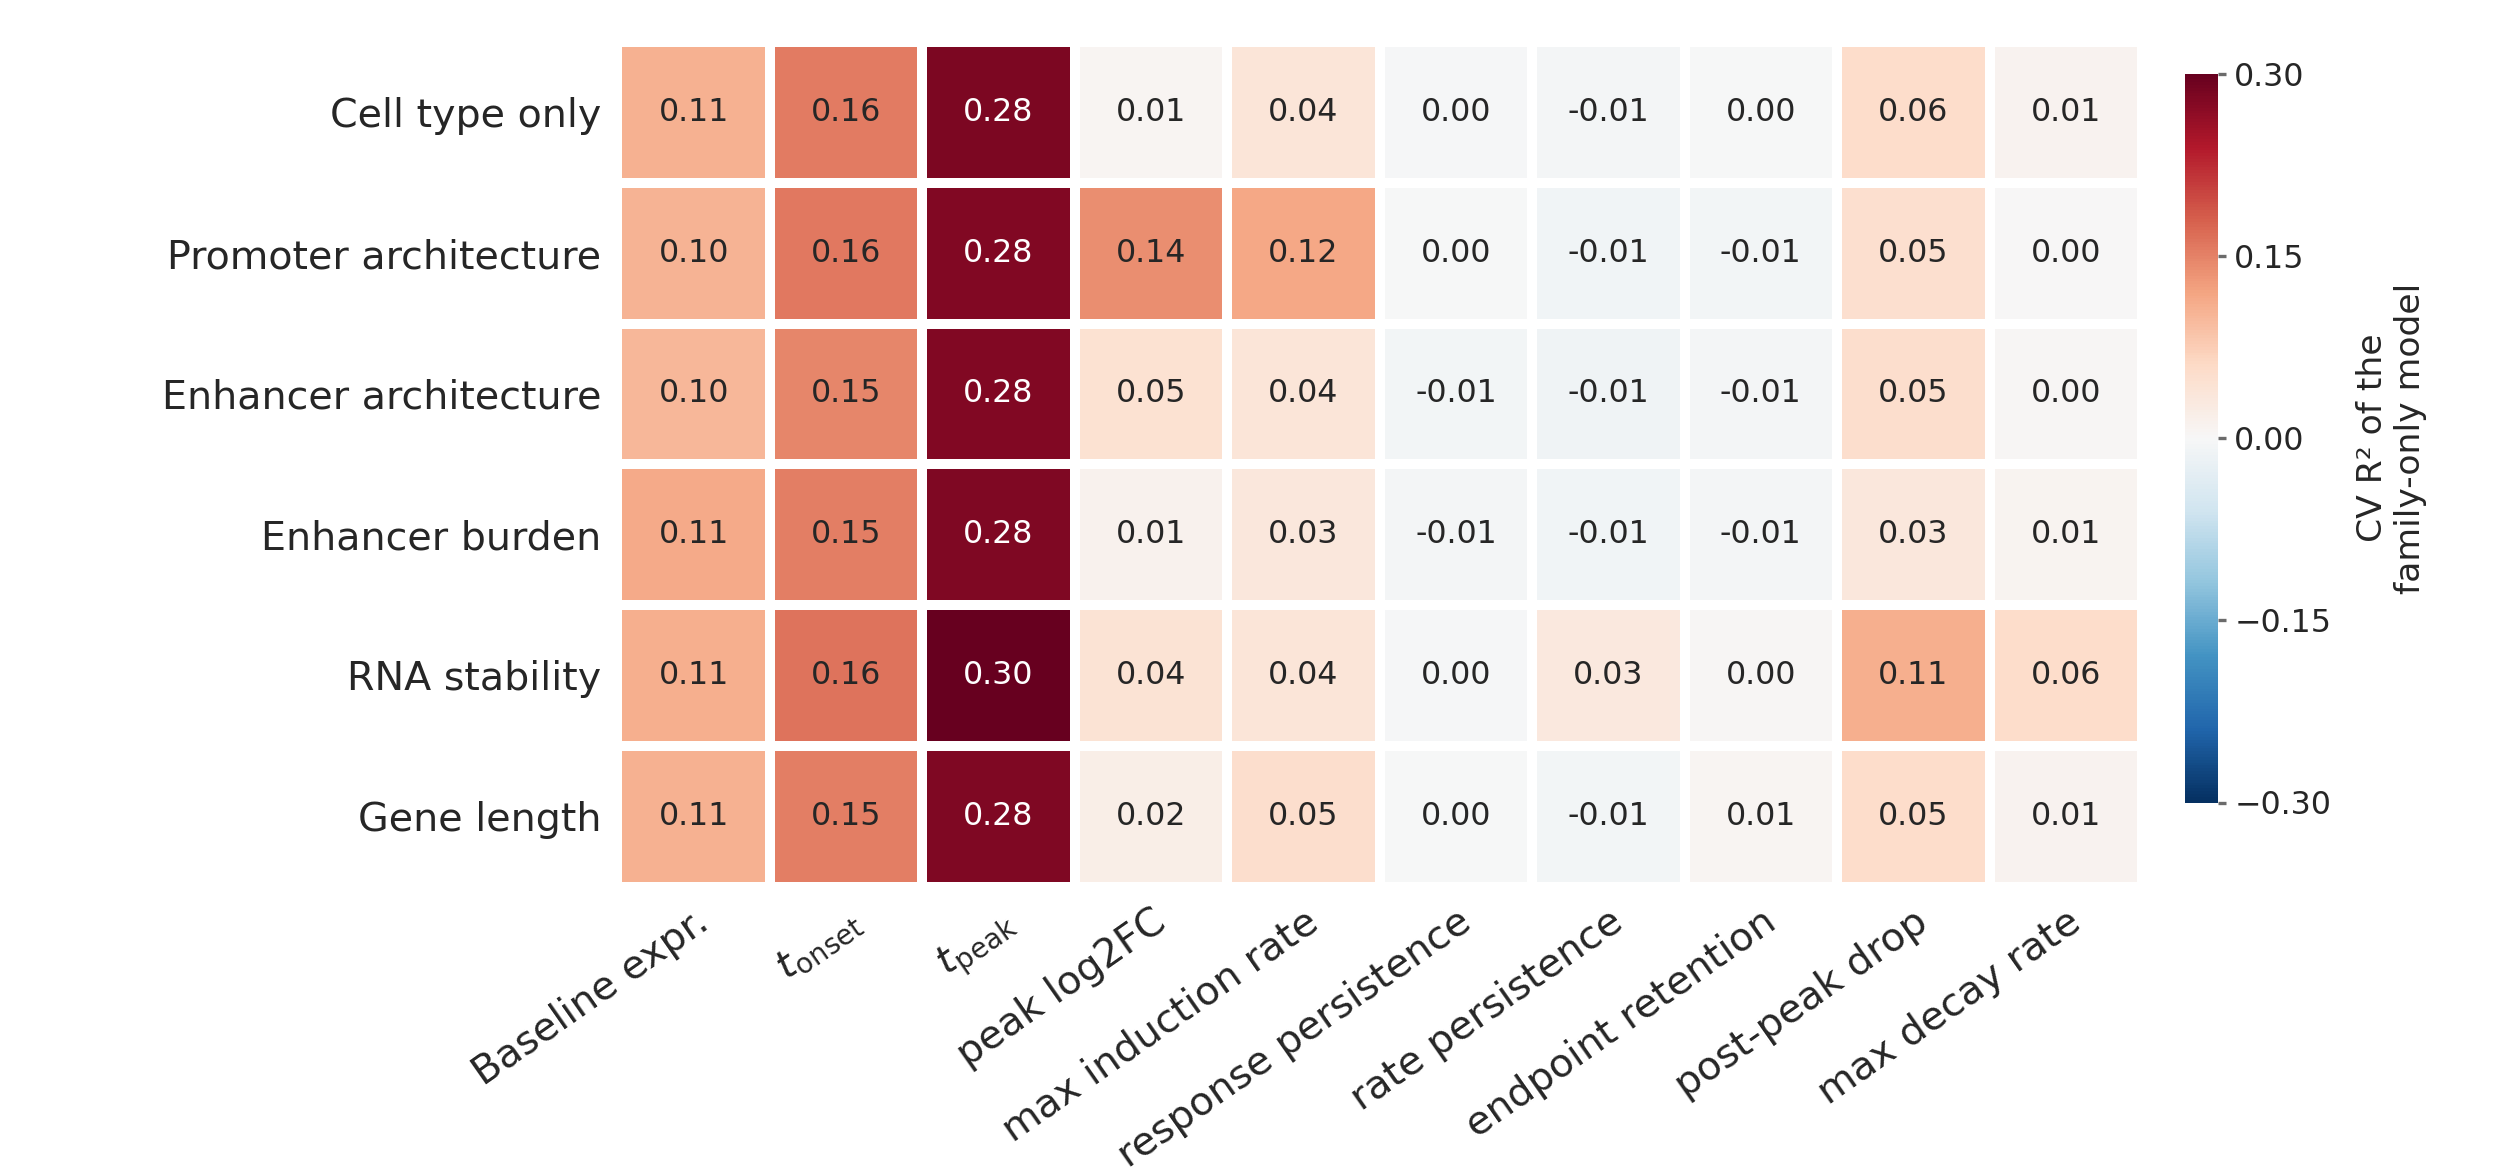

outcome,baseline_exp,endpoint_retention,max_decay_rate,max_induction_rate,owp,owp_ddt,peak_log2fc,postpeak_drop,t_onset,t_peak
family_label,,,,,,,,,,
Enhancer architecture,-0.007,-0.004,-0.007,0.000,-0.004,-0.007,0.042,-0.003,-0.009,-0.005
Enhancer burden,0.007,-0.004,-0.005,-0.005,-0.003,-0.005,0.008,-0.021,-0.001,-0.003
Gene length,-0.000,0.007,-0.001,0.012,0.002,-0.004,0.015,-0.001,-0.000,-0.002
Promoter architecture,-0.003,-0.006,-0.010,0.076,0.002,-0.006,0.134,-0.005,0.002,-0.003
RNA stability,0.001,0.005,0.044,0.000,-0.001,0.036,0.038,0.054,0.007,0.016


In [9]:
fam_prefix = "output/fig6_family_only_cv_r2"
if needs_run([fam_prefix + "_gain.png", fam_prefix + "_raw.png", fam_prefix + "_values.csv"], RERUN):
    reset_style(); de.set_style()
    fam_r2.main()
show_image(fam_prefix + "_gain.png", width=850)
show_image(fam_prefix + "_raw.png", width=850)
pd.read_csv(FIG_DIR / (fam_prefix + "_values.csv")).pivot(index="family_label", columns="outcome", values="r2_gain_over_celltype").round(3)

## Checks: inputs and comparison with v1

`compare_to_v1.py` checks every input against `Fig6_Reproduction/reference/manifest.json`, confirms the dot plot
and the 6e values are unchanged from `Fig6_CrossContext/` (same tables), and reports how 6d, the full-model figure and
the family-only models changed between Run3 and v4.

In [10]:
run([sys.executable, "scripts/compare_to_v1.py"])
show_text("output/comparison_to_v1.txt")

$ /new-stg/home/alex/miniconda3/envs/chronopack/bin/python scripts/compare_to_v1.py


== 1. inputs vs Fig6_Reproduction/reference/manifest.json
  [OK] ORA_results_v2_newbg_newfg4.csv sha256 matches the reference manifest
  [OK] canonical9_ols_results.csv sha256 matches the reference manifest
  [OK] curated_ordered_grouped_specific_terms.csv sha256 matches the reference manifest
  [OK] cv_celltype_only_results.csv sha256 matches the reference manifest
  [OK] cv_summary_results.csv sha256 matches the reference manifest
  [OK] logistic_regression_screen_results_v3_b3_pctl_fg4.csv sha256 matches the reference manifest
  [OK] motif_summary_S10_CRE-matched_with_counts.csv sha256 matches the reference manifest
  [OK] tata_box_positional_S10_summary_with_counterfactual_q.csv sha256 matches the reference manifest
  [OK] input/ holds exactly the eight reference tables

== 2. dot plot vs v1
  [OK] fig6_ora_cov_pls_motifs_transposed_v2_pctl_fg4_q05.png pixel-identical to v1
  [OK] fig6_ora_cov_pls_motifs_transposed_v2_pctl_fg4_q05_points.csv identical to v1

== 3. 6e vs v1
  [OK] c